setup and imports

In [10]:
!git clone https://github.com/Mukasa-E/Formative-2-HMM.git


import shutil
import os

repo_name = "Formative-2-HMM"
if os.path.exists(repo_name):
    for item in os.listdir(repo_name):
        shutil.move(os.path.join(repo_name, item), ".")

    shutil.rmtree(repo_name)

print("Workspace updated successfully. Current directory files:", os.listdir("."))

Cloning into 'Formative-2-HMM'...
remote: Enumerating objects: 136, done.
remote: Counting objects: 100% (136/136), done.
remote: Compressing objects: 100% (95/95), done.
remote: Total 136 (delta 36), reused 136 (delta 36), pack-reused 0 (from 0)
Receiving objects: 100% (136/136), 1.35 MiB | 13.20 MiB/s, done.
Resolving deltas: 100% (36/36), done.
Workspace updated successfully. Current directory files: ['.config', 'notebooks', '.git', 'data', 'README.md', 'report', 'videos', 'figures', 'convert_real_data.py', 'src', '.gitattributes', 'sample_data']


In [15]:
import os
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current_dir = os.getcwd()
if current_dir not in sys.path:
    sys.path.insert(0, current_dir)
src_dir = os.path.join(current_dir, "src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)

importlib.invalidate_caches()

BASE_DIR = current_dir
TRAIN_DIR = os.path.join(BASE_DIR, "data", "train")
TEST_DIR = os.path.join(BASE_DIR, "data", "test")
SAMPLING_RATE_HZ = 50
ACTIVITIES = ["standing", "walking", "jumping", "still"]

from src.features import extract_all_features_from_dir, z_score_normalize
from src.hmm import DiscreteHMM
from src.visualization import (
    plot_transition_matrix,
    plot_emission_matrix,
    plot_decoded_sequence,
    plot_confusion_matrix,
    plot_sample_signals,
    plot_log_likelihood,
    compute_metrics,
)

from collections import Counter

print("Imports successful.")
print(f"Activities: {ACTIVITIES}")
print(f"Sampling rate: {SAMPLING_RATE_HZ} Hz")

Imports successful.
Activities: ['standing', 'walking', 'jumping', 'still']
Sampling rate: 50 Hz


sample raw signal

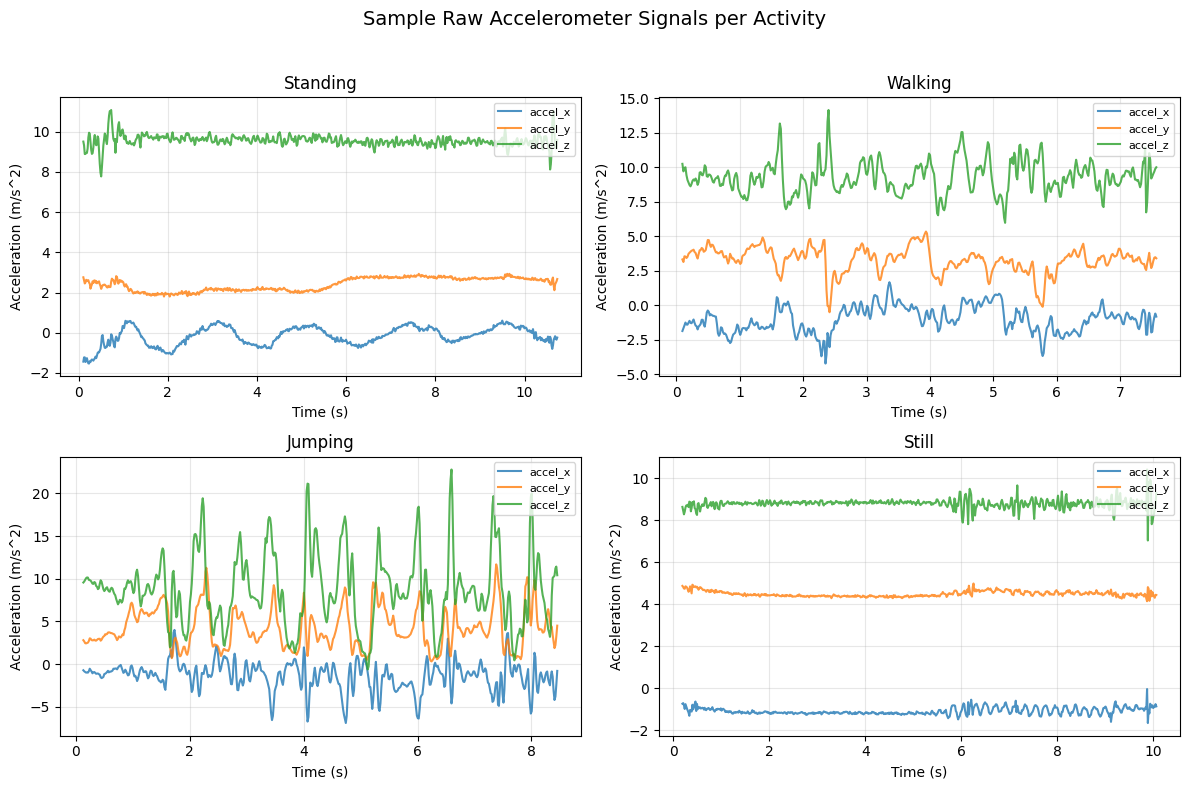

In [16]:
plot_sample_signals(TRAIN_DIR, activities=ACTIVITIES, save_path="figures/sample_signals.png", fs=SAMPLING_RATE_HZ)

Feature extraction

In [17]:
WINDOW_SEC = 2.0
N_OBS = 20
N_HIDDEN = 4


X_train_raw, y_train, train_info, feature_names = extract_all_features_from_dir(
    TRAIN_DIR, window_sec=WINDOW_SEC
)
print(f"Training windows: {X_train_raw.shape[0]}")
print(f"Feature names: {feature_names}")
print(f"Files per activity: {{a: sum(1 for i in train_info if i['activity']==a) for a in ACTIVITIES}}")

X_train, mean, std = z_score_normalize(X_train_raw)
print(f"\nZ-score normalization applied.")
print(f"Mean: {np.round(mean, 3)}")
print(f"Std:  {np.round(std, 3)}")

X_train_symbols, bin_edges = DiscreteHMM.encode_observations(X_train, n_obs=N_OBS, random_state=42)
train_lengths = [info["n_windows"] for info in train_info]
print(f"\nDiscretised to {N_OBS} observation symbols.")
print(f"Number of training sequences (files): {len(train_lengths)}")

Training windows: 43
Feature names: ['sma', 'mean_accel', 'var_accel', 'dom_freq', 'spec_energy']
Files per activity: {a: sum(1 for i in train_info if i['activity']==a) for a in ACTIVITIES}

Z-score normalization applied.
Mean: [9.9580000e+00 9.9580000e+00 5.3490000e+00 3.9670000e+00 4.1792919e+04]
Std:  [1.4800000e-01 1.4800000e-01 1.1958000e+01 3.5900000e+00 9.3418716e+04]

Discretised to 20 observation symbols.
Number of training sequences (files): 11


Hmm setup and implementation

In [18]:
WINDOW_SEC = 2.0
N_OBS = 20
N_HIDDEN = 4

X_train_raw, y_train, train_info, feature_names = extract_all_features_from_dir(
    TRAIN_DIR, window_sec=WINDOW_SEC
)
print(f"Training windows: {X_train_raw.shape[0]}")
print(f"Feature names: {feature_names}")
print(f"Files per activity: {{a: sum(1 for i in train_info if i['activity']==a) for a in ACTIVITIES}}")

X_train, mean, std = z_score_normalize(X_train_raw)
print(f"\nZ-score normalization applied.")
print(f"Mean: {np.round(mean, 3)}")
print(f"Std:  {np.round(std, 3)}")

X_train_symbols, bin_edges = DiscreteHMM.encode_observations(X_train, n_obs=N_OBS, random_state=42)
train_lengths = [info["n_windows"] for info in train_info]
print(f"\nDiscretised to {N_OBS} observation symbols.")
print(f"Number of training sequences (files): {len(train_lengths)}")

Training windows: 43
Feature names: ['sma', 'mean_accel', 'var_accel', 'dom_freq', 'spec_energy']
Files per activity: {a: sum(1 for i in train_info if i['activity']==a) for a in ACTIVITIES}

Z-score normalization applied.
Mean: [9.9580000e+00 9.9580000e+00 5.3490000e+00 3.9670000e+00 4.1792919e+04]
Std:  [1.4800000e-01 1.4800000e-01 1.1958000e+01 3.5900000e+00 9.3418716e+04]

Discretised to 20 observation symbols.
Number of training sequences (files): 11


In [22]:
import inspect
from src.hmm import DiscreteHMM

sig = inspect.signature(DiscreteHMM.__init__)
print("DiscreteHMM constructor signature:", sig)

params = {}
sig_params = list(sig.parameters.keys())

if 'n_states' in sig_params:
    params['n_states'] = N_HIDDEN
elif 'n_components' in sig_params:
    params['n_components'] = N_HIDDEN
elif 'n_hidden' in sig_params:
    params['n_hidden'] = N_HIDDEN
else:

    pass

if 'n_obs' in sig_params:
    params['n_obs'] = N_OBS
elif 'n_observations' in sig_params:
    params['n_observations'] = N_OBS

if 'random_state' in sig_params:
    params['random_state'] = 42

try:
    if params:
        model = DiscreteHMM(**params)
    else:

        model = DiscreteHMM(N_HIDDEN, N_OBS, random_state=42)
    print("Model instantiated successfully!")
except Exception as e:
    print("Error during instantiation:", e)

    model = DiscreteHMM(N_HIDDEN, N_OBS)
    print("Model instantiated successfully with positional arguments!")

print("Fitting Hidden Markov Model on training sequences...")
model.fit(X_train_symbols, train_lengths)
print("Model training complete!")

DiscreteHMM constructor signature: (self, n_hidden=4, n_obs=20, random_state=42)
Model instantiated successfully!
Fitting Hidden Markov Model on training sequences...
  Iter   1: log-likelihood = -127.6061
  Iter  11: log-likelihood = -32.1587
  Iter  21: log-likelihood = -31.3900
  Iter  31: log-likelihood = -31.2094
  Iter  41: log-likelihood = -31.0981
  Iter  51: log-likelihood = -31.0478
  Iter  61: log-likelihood = -30.9943
  Iter  71: log-likelihood = -30.7750
  Iter  81: log-likelihood = -30.5678
  Iter  91: log-likelihood = -30.5377
  Converged at iteration 98 (delta log-likelihood = 9.41e-05 < 0.0001)
Model training complete!


Evaluation on unseen data

In [24]:
from collections import Counter

X_test_raw, y_test, test_info, _ = extract_all_features_from_dir(TEST_DIR, window_sec=WINDOW_SEC)
X_test, _, _ = z_score_normalize(X_test_raw, mean=mean, std=std)
X_test_symbols, _ = DiscreteHMM.encode_observations(X_test, n_obs=N_OBS, random_state=42)
test_lengths = [info["n_windows"] for info in test_info]

state_to_activity = {}
for s in range(N_HIDDEN):
    mask = model.predict(X_train_symbols) == s
    if mask.sum() > 0:
        state_to_activity[s] = Counter(y_train[mask]).most_common(1)[0][0]
    else:
        state_to_activity[s] = ACTIVITIES[s]

print("State -> activity mapping:", state_to_activity)

y_test_pred = []
y_test_true = []
seq_idx = 0
for info in test_info:
    n_win = info["n_windows"]
    seq_symbols = X_test_symbols[seq_idx:seq_idx + n_win]
    pred_states = model.predict(seq_symbols)
    pred_activities = [state_to_activity[s] for s in pred_states]
    y_test_pred.extend(pred_activities)
    y_test_true.extend([info["activity"]] * n_win)
    seq_idx += n_win

y_test_pred = np.array(y_test_pred)
y_test_true = np.array(y_test_true)
print(f"\nTest windows predicted: {len(y_test_pred)}")

State -> activity mapping: {0: np.str_('walking'), 1: np.str_('jumping'), 2: np.str_('walking'), 3: np.str_('standing')}

Test windows predicted: 30


In [34]:
import numpy as np
import matplotlib.pyplot as plt
from src.visualization import compute_metrics, plot_confusion_matrix, plot_transition_matrix, plot_emission_matrix

results = compute_metrics(y_test_true, y_test_pred, activities=ACTIVITIES)

print("=== Per-Class Performance Metrics ===")
for activity, metrics in results.items():
    if activity.lower() != 'overall':
        print(f"\nActivity: {activity.upper()}")
        print(f"  Sensitivity (Recall): {metrics.get('sensitivity', 0.0):.3f}")
        print(f"  Specificity:          {metrics.get('specificity', 0.0):.3f}")
        print(f"  True Positives (TP):  {metrics.get('tp', 0)}")
        print(f"  False Negatives (FN): {metrics.get('fn', 0)}")
        print(f"  False Positives (FP): {metrics.get('fp', 0)}")
        print(f"  True Negatives (TN):  {metrics.get('tn', 0)}")

correct_predictions = sum(y_test_pred == y_test_true)
total_predictions = len(y_test_true)
overall_accuracy = correct_predictions / total_predictions
print(f"\nOverall Accuracy: {overall_accuracy:.3f} ({correct_predictions}/{total_predictions})")

plt.figure(figsize=(8, 6))

plot_confusion_matrix(y_test_true, y_test_pred, activities=ACTIVITIES, title="HMM Confusion Matrix")
plt.show()

plt.figure(figsize=(6, 5))
plot_transition_matrix(model.transmat_)
plt.show()

plt.figure(figsize=(10, 6))
plot_emission_matrix(model.emissionprob_)
plt.show()

=== Per-Class Performance Metrics ===

Activity: STANDING
  Sensitivity (Recall): 0.286
  Specificity:          0.652
  True Positives (TP):  2
  False Negatives (FN): 5
  False Positives (FP): 8
  True Negatives (TN):  15

Activity: WALKING
  Sensitivity (Recall): 0.714
  Specificity:          0.652
  True Positives (TP):  5
  False Negatives (FN): 2
  False Positives (FP): 8
  True Negatives (TN):  15

Activity: JUMPING
  Sensitivity (Recall): 0.250
  Specificity:          0.773
  True Positives (TP):  2
  False Negatives (FN): 6
  False Positives (FP): 5
  True Negatives (TN):  17

Activity: STILL
  Sensitivity (Recall): 0.000
  Specificity:          1.000
  True Positives (TP):  0
  False Negatives (FN): 8
  False Positives (FP): 0
  True Negatives (TN):  22

Overall Accuracy: 0.300 (9/30)


In [32]:
model_attributes = [attr for attr in dir(model) if not attr.startswith('__')]
print("Model attributes:", model_attributes)

Model attributes: ['_forward', '_init_parameters', '_logsumexp', 'converged_', 'emissionprob_', 'encode_observations', 'fit', 'log_likelihoods_', 'n_hidden', 'n_iter_', 'n_obs', 'predict', 'predict_proba', 'random_state', 'rng', 'score', 'startprob_', 'transmat_']


In [35]:
#metrics
metrics = compute_metrics(y_test_true, y_test_pred, activities=ACTIVITIES)

print("Evaluation results (unseen test data):")
print(f"{'Activity':<12} {'Sensitivity':>12} {'Specificity':>12} {'Support':>10}")
print("-" * 58)
for activity in ACTIVITIES:
    m = metrics[activity]
    print(f"{activity:<12} {m['sensitivity']:>12.3f} {m['specificity']:>12.3f} {m['support']:>10}")
print("-" * 58)
print(f"{'OVERALL ACCURACY':<12} {metrics['overall']['accuracy']:>12.3f}")

Evaluation results (unseen test data):
Activity      Sensitivity  Specificity    Support
----------------------------------------------------------
standing            0.286        0.652          7
walking             0.714        0.652          7
jumping             0.250        0.773          8
still               0.000        1.000          8
----------------------------------------------------------
OVERALL ACCURACY        0.300


Visualizations


In [36]:
os.makedirs("figures", exist_ok=True)

#transition matrix heatmap
plot_transition_matrix(model.transmat_, activities=ACTIVITIES,
                       save_path="figures/transition_matrix.png")

#emission matrix heatmap
plot_emission_matrix(model.emissionprob_, activities=ACTIVITIES,
                     save_path="figures/emission_matrix.png")

#baum-Welch convergence
plot_log_likelihood(model.log_likelihoods_,
                    save_path="figures/convergence.png")

#confusion matrix
plot_confusion_matrix(y_test_true, y_test_pred, activities=ACTIVITIES,
                      save_path="figures/confusion_matrix.png",
                      title="Confusion Matrix — Unseen Test Data")

#decoded sequence (first test file)
first_test = test_info[0]
n_win = first_test["n_windows"]
seq_symbols = X_test_symbols[:n_win]
pred_states = model.predict(seq_symbols)
activity_to_state = {a: s for s, a in state_to_activity.items()}
true_state_indices = np.array([activity_to_state[first_test["activity"]]] * n_win)
plot_decoded_sequence(true_state_indices, pred_states, activities=ACTIVITIES,
                      save_path="figures/decoded_sequence.png")

print("All figures saved to figures/")

All figures saved to figures/


Transition and emission matrices

In [37]:
import pandas as pd

#transition matrix
trans_df = pd.DataFrame(model.transmat_, index=ACTIVITIES, columns=ACTIVITIES)
print("Transition Matrix (A):")
print(trans_df.round(3))
print()

#emission matrix (shape: n_hidden x n_obs)
emi_df = pd.DataFrame(model.emissionprob_, index=ACTIVITIES)
print("Emission Matrix (B) — first 10 observation symbols:")
print(emi_df.iloc[:, :10].round(3))

Transition Matrix (A):
          standing  walking  jumping  still
standing     0.344    0.656      0.0  0.000
walking      0.000    1.000      0.0  0.000
jumping      0.544    0.000      0.0  0.456
still        0.000    0.000      0.0  1.000

Emission Matrix (B) — first 10 observation symbols:
             0    1    2    3    4      5    6      7    8    9
standing  0.00  0.0  0.0  0.0  0.0  0.302  0.0  0.192  0.0  0.0
walking   0.08  0.0  0.0  0.0  0.0  0.000  0.0  0.087  0.0  0.0
jumping   0.00  0.0  0.0  0.0  0.0  0.000  0.0  0.000  0.0  0.0
still     0.00  0.0  1.0  0.0  0.0  0.000  0.0  0.000  0.0  0.0
